In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

'pip' is not recognized as an internal or external command,
operable program or batch file.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_excel("Online Retail.xlsx")
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 8)


In [8]:
df = df.dropna(subset=['CustomerID'])
print("Shape after removing missing Customer IDs:", df.shape)

Shape after removing missing Customer IDs: (401604, 8)


In [9]:
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.startswith('C')]
print("Shape after removing cancelled transactions:", df.shape)

Shape after removing cancelled transactions: (392732, 8)


In [10]:
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print("Final cleaned dataset:", df.shape)

Final cleaned dataset: (392692, 8)


In [11]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [12]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalAmount
count,392692.000000,392692,392692.000000,392692.000000,392692.000000
mean,13.119702,2011-07-10 19:13:07.771892,3.125914,15287.843865,22.631500
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,2.000000,2011-04-07 11:12:00,1.250000,13955.000000,4.950000
50%,6.000000,2011-07-31 12:02:00,1.950000,15150.000000,12.450000
75%,12.000000,2011-10-20 12:53:00,3.750000,16791.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,180.492832,NaN,22.241836,1713.539549,311.099224


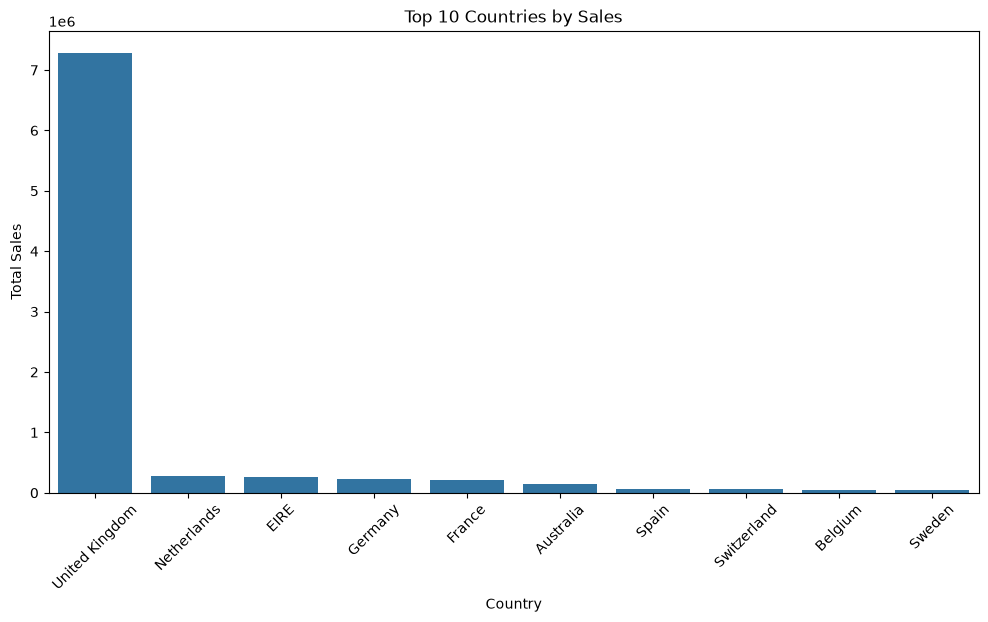

In [13]:
country_sales = df.groupby('Country')['TotalAmount'].sum()
country_sales = country_sales.sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
sns.barplot(x=country_sales.index, y=country_sales.values)
plt.title("Top 10 Countries by Sales")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

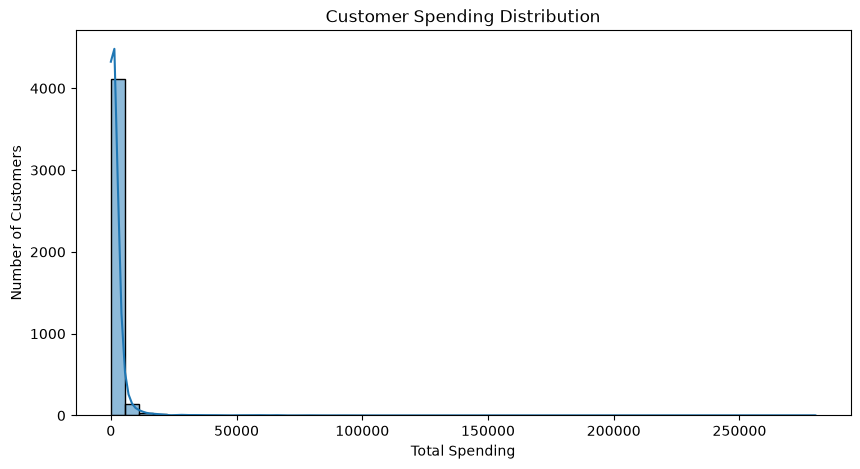

In [14]:
customer_spending = df.groupby('CustomerID')['TotalAmount'].sum()
plt.figure(figsize=(10,5))
sns.histplot(customer_spending, bins=50, kde=True)
plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending")
plt.ylabel("Number of Customers")
plt.show()

In [15]:
order_totals = df.groupby(
    ['CustomerID', 'InvoiceNo']
)['TotalAmount'].sum().reset_index(name='OrderValue')

In [16]:
customer_features = df.groupby('CustomerID').agg({
    'TotalAmount': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
}).reset_index()

customer_features.columns = [
    'CustomerID',
    'TotalAmount',
    'TotalQuantity',
    'NumberOfOrders'
]

In [17]:
avg_order_value = order_totals.groupby(
    'CustomerID'
)['OrderValue'].mean().reset_index()

avg_order_value.columns = [
    'CustomerID',
    'AverageOrderValue'
]

In [18]:
customer_features = customer_features.merge(
    avg_order_value,
    on='CustomerID'
)

customer_features.head()

,CustomerID,TotalAmount,TotalQuantity,NumberOfOrders,AverageOrderValue
0,12346.0,77183.60,74215,1,77183.600000
1,12347.0,4310.00,2458,7,615.714286
2,12348.0,1797.24,2341,4,449.310000
3,12349.0,1757.55,631,1,1757.550000
4,12350.0,334.40,197,1,334.400000


In [19]:
customer_features.shape

(4338, 5)

In [20]:
customer_features.isnull().sum()

CustomerID           0
TotalAmount          0
TotalQuantity        0
NumberOfOrders       0
AverageOrderValue    0
dtype: int64

In [21]:
features = [
    'TotalAmount',
    'TotalQuantity',
    'NumberOfOrders',
    'AverageOrderValue'
]
X = customer_features[features]

In [22]:
X_log = np.log1p(X)

In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

In [24]:
X_scaled[:5]

array([[ 3.7077163 ,  3.8189491 , -0.95521426,  7.52280682],
       [ 1.41490344,  1.33269016,  1.07442519,  1.04416007],
       [ 0.72002428,  1.29711755,  0.38630445,  0.6223117 ],
       [ 0.70228691,  0.34130193, -0.95521426,  2.4497941 ],
       [-0.61451388, -0.50560654, -0.95521426,  0.227101  ]])

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [26]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=min(2000, len(X_scaled)),
        random_state=42
    )

    silhouette_scores.append(score)

    print("K =", k, "| Silhouette Score =", round(score, 4))

K = 2 | Silhouette Score = 0.4173
K = 3 | Silhouette Score = 0.3366
K = 4 | Silhouette Score = 0.3173
K = 5 | Silhouette Score = 0.3267
K = 6 | Silhouette Score = 0.3205
K = 7 | Silhouette Score = 0.3052
K = 8 | Silhouette Score = 0.2996
K = 9 | Silhouette Score = 0.3067
K = 10 | Silhouette Score = 0.308


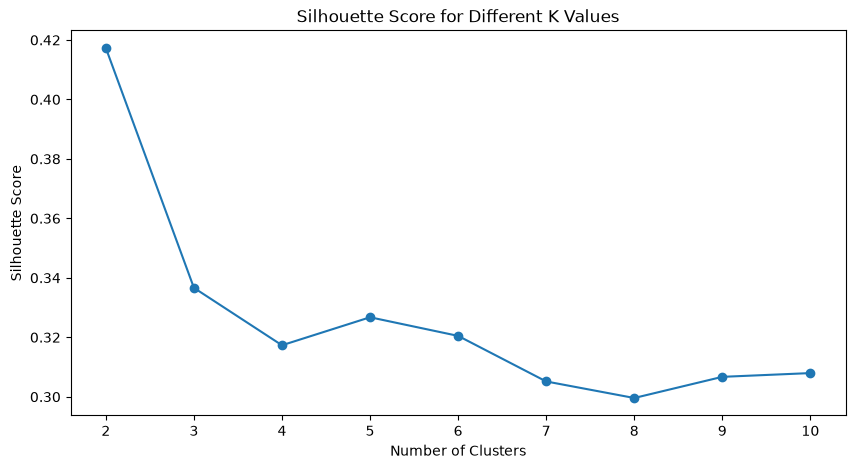

In [27]:
plt.figure(figsize=(10,5))

plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.show()

In [28]:
best_k = range(2, 11)[
    np.argmax(silhouette_scores)
]

print("Selected number of clusters:", best_k)

Selected number of clusters: 2


In [29]:
final_model = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

customer_features['Cluster'] = final_model.fit_predict(X_scaled)

In [30]:
customer_features['Cluster'].value_counts().sort_index()

Cluster
0    1814
1    2524
Name: count, dtype: int64

In [31]:
final_score = silhouette_score(
    X_scaled,
    customer_features['Cluster'],
    sample_size=min(2000, len(X_scaled)),
    random_state=42
)

print("Final Silhouette Score:", round(final_score, 4))

Final Silhouette Score: 0.4173


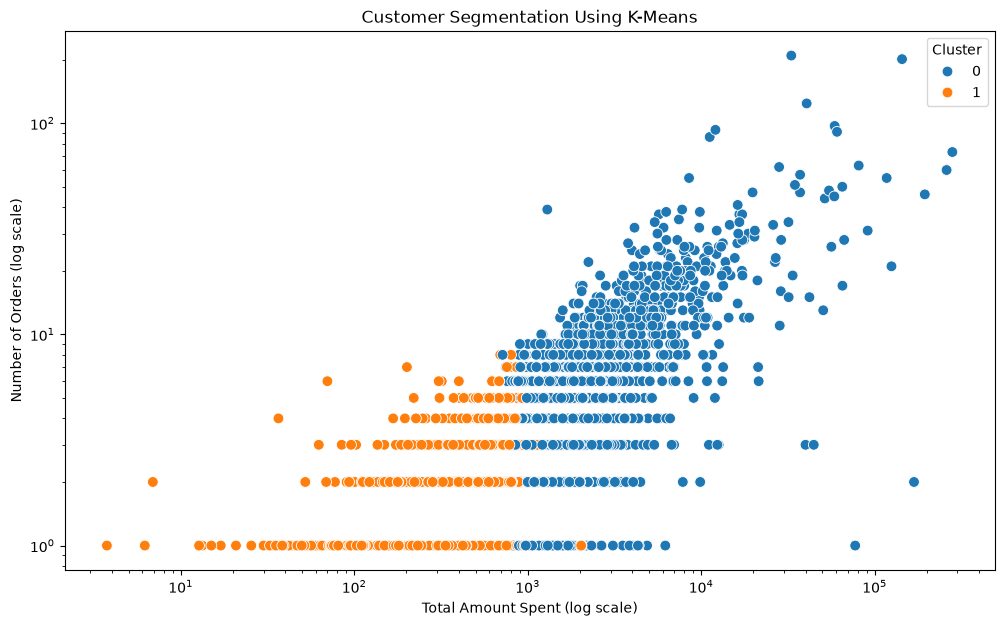

In [32]:
plt.figure(figsize=(12,7))

sns.scatterplot(
    data=customer_features,
    x='TotalAmount',
    y='NumberOfOrders',
    hue='Cluster',
    palette='tab10',
    s=60
)
plt.xscale('log')
plt.yscale('log')
plt.title("Customer Segmentation Using K-Means")
plt.xlabel("Total Amount Spent (log scale)")
plt.ylabel("Number of Orders (log scale)")
plt.show()

In [33]:
cluster_analysis = customer_features.groupby('Cluster').agg({
    'TotalAmount': 'median',
    'TotalQuantity': 'median',
    'NumberOfOrders': 'median',
    'AverageOrderValue': 'median',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'NumberOfCustomers'})

cluster_analysis

,TotalAmount,TotalQuantity,NumberOfOrders,AverageOrderValue,NumberOfCustomers
Cluster,,,,,
0,1972.130,1178.0,5.0,399.689405,1814
1,339.125,187.0,1.0,209.637500,2524


In [34]:
customer_features.to_csv(
    'customer_segments.csv',
    index=False
)

print("Customer segmentation results saved successfully!")

Customer segmentation results saved successfully!


In [35]:
import os

os.makedirs("outputs", exist_ok=True)
print("Output folder created successfully!")

Output folder created successfully!


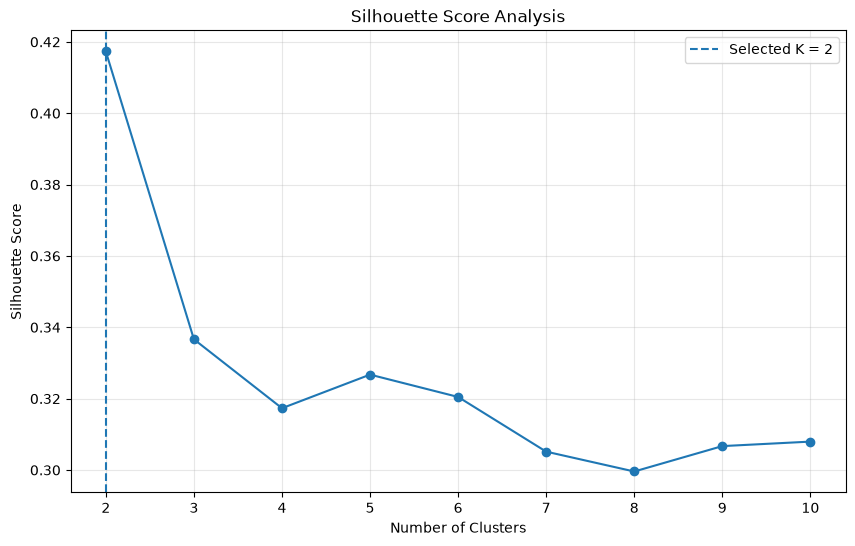

In [36]:
plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.axvline(
    best_k,
    linestyle='--',
    label=f'Selected K = {best_k}'
)

plt.title("Silhouette Score Analysis")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")

plt.legend()
plt.grid(alpha=0.3)

plt.savefig("outputs/silhouette_analysis.png", dpi=300, bbox_inches="tight")

plt.show()

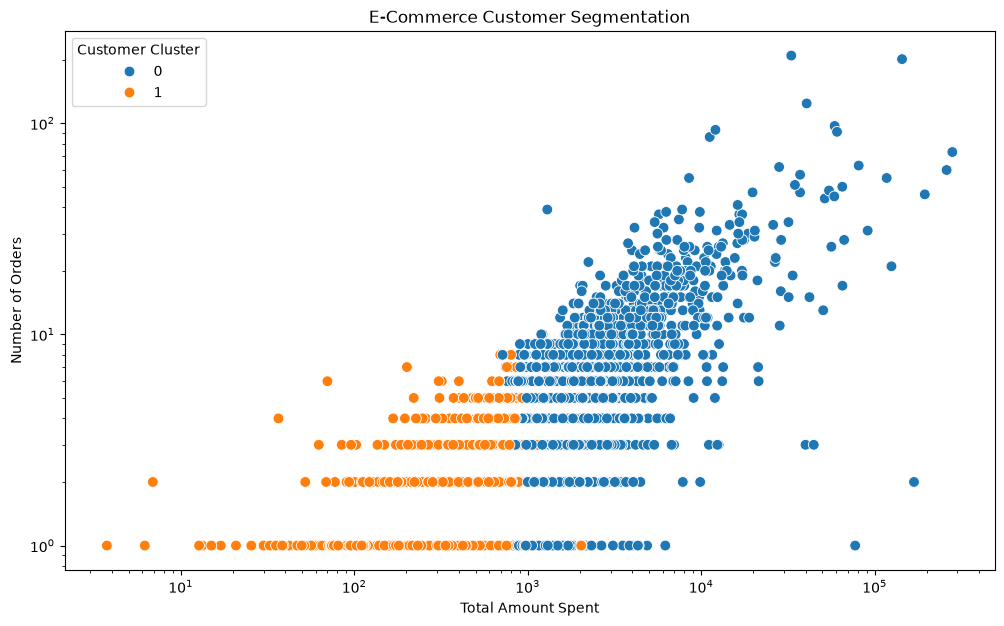

In [37]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=customer_features,
    x='TotalAmount',
    y='NumberOfOrders',
    hue='Cluster',
    palette='tab10',
    s=60
)

plt.xscale('log')
plt.yscale('log')

plt.title("E-Commerce Customer Segmentation")
plt.xlabel("Total Amount Spent")
plt.ylabel("Number of Orders")
plt.legend(title="Customer Cluster")

plt.savefig(
    "outputs/customer_segments.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
cluster_summary = customer_features.groupby('Cluster').agg(
    Number_of_Customers=('CustomerID', 'count'),
    Median_Spending=('TotalAmount', 'median'),
    Median_Quantity=('TotalQuantity', 'median'),
    Median_Orders=('NumberOfOrders', 'median'),
    Median_Order_Value=('AverageOrderValue', 'median')
)

cluster_summary['Customer_Percentage'] = (
    cluster_summary['Number_of_Customers']
    / len(customer_features) * 100
)

cluster_summary = cluster_summary.round(2)

display(cluster_summary)

,Number_of_Customers,Median_Spending,Median_Quantity,Median_Orders,Median_Order_Value,Customer_Percentage
Cluster,,,,,,
0,1814,1972.13,1178.0,5.0,399.69,41.82
1,2524,339.12,187.0,1.0,209.64,58.18


In [39]:
cluster_summary.to_csv(
    "outputs/cluster_summary.csv"
)

print("Cluster summary exported successfully!")

Cluster summary exported successfully!


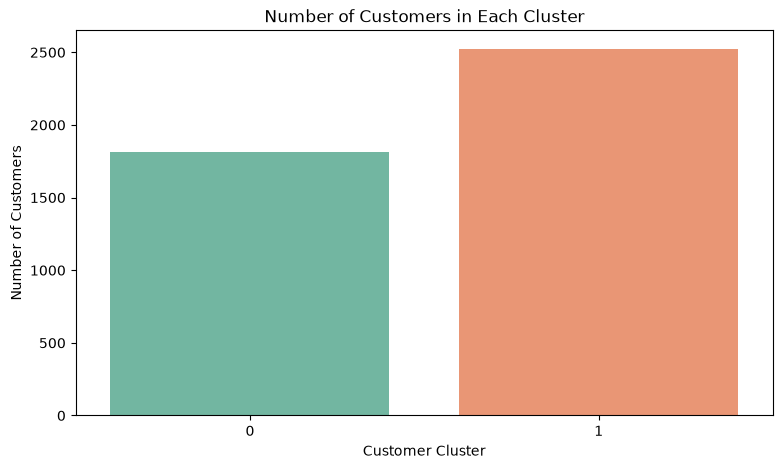

In [40]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=customer_features,
    x='Cluster',
    hue='Cluster',
    palette='Set2',
    legend=False
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")

plt.savefig(
    "outputs/cluster_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
print("========== K-MEANS PROJECT RESULTS ==========")

print("\n1. Selected Number of Clusters (K):")
print(best_k)

print("\n2. Final Silhouette Score:")
print(round(final_score, 4))

print("\n3. Total Customers:")
print(len(customer_features))

print("\n4. Customer Distribution:")
print(customer_features['Cluster'].value_counts().sort_index())

print("\n5. Cluster Summary:")
display(cluster_summary)

print("\n6. Missing Values:")
print(customer_features.isnull().sum())

print("\n========== PROJECT COMPLETE ==========")

========== K-MEANS PROJECT RESULTS ==========

1. Selected Number of Clusters (K):
2

2. Final Silhouette Score:
0.4173

3. Total Customers:
4338

4. Customer Distribution:
Cluster
0    1814
1    2524
Name: count, dtype: int64

5. Cluster Summary:


,Number_of_Customers,Median_Spending,Median_Quantity,Median_Orders,Median_Order_Value,Customer_Percentage
Cluster,,,,,,
0,1814,1972.13,1178.0,5.0,399.69,41.82
1,2524,339.12,187.0,1.0,209.64,58.18



6. Missing Values:
CustomerID           0
TotalAmount          0
TotalQuantity        0
NumberOfOrders       0
AverageOrderValue    0
Cluster              0
dtype: int64

========== PROJECT COMPLETE ==========


In [42]:
with open("outputs/project_results.txt", "w") as f:
    f.write(f"Best K: {best_k}\n")
    f.write(f"Silhouette Score: {final_score:.4f}\n")
    f.write(f"Total Customers: {len(customer_features)}\n\n")
    f.write(cluster_summary.to_string())

print("Results saved successfully!")

Results saved successfully!


In [43]:
readme = f"""
# E-Commerce Customer Segmentation Using K-Means

## Project Overview
This project uses unsupervised machine learning to segment e-commerce customers according to their purchasing behaviour.

## Objective
Identify customer groups based on spending, purchase quantity, order frequency and average order value.

## Dataset
UCI Online Retail Dataset:
https://archive.ics.uci.edu/dataset/352/online+retail

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Jupyter Notebook

## Project Workflow
1. Dataset Loading
2. Data Cleaning
3. Exploratory Data Analysis
4. Customer-Level Feature Engineering
5. Feature Scaling
6. Silhouette Score Analysis
7. K-Means Clustering
8. Cluster Evaluation
9. Customer Segment Visualization
10. Business Insights

## Features Used
- Total Amount Spent
- Total Quantity Purchased
- Number of Orders
- Average Order Value

## Model Results
- Total Customers: {len(customer_features)}
- Selected Number of Clusters: {best_k}
- Final Silhouette Score: {final_score:.4f}

## Project Outputs
- Silhouette Score Analysis
- Customer Segmentation Visualization
- Cluster Distribution
- Customer Cluster Summary

## How to Run
1. Clone this repository.
2. Install dependencies using:

   pip install -r requirements.txt

3. Download the UCI Online Retail dataset.
4. Place the Excel file inside the data folder.
5. Open Customer_Segmentation.ipynb.
6. Run all cells.

## Disclaimer
This project is developed for educational and analytical purposes.

## Author
Garv Dubey
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")

README.md created successfully!
